In [1]:
from utils import *

%load_ext autoreload
%autoreload 2

import utils

/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# !pip install pandas scikit-learn spacy contractions fasttext
# !python -m spacy download en_core_web_sm
# !pip install pandas scikit-learn spacy contractions pybind11
# !pip install fasttext
# !python -m spacy download en_core_web_sm
# pip install hdbscan
# pip install bertopic hdbscan umap-learn sentence-transformers gensim
# pip install sentence-transformers
# pip install matplotlib

In [3]:
# # sentence level summary

# summary = "sentence"
# import pandas as pd
# from functools import reduce
# import pandas as pd
# from utils import *
# df_ls = []  
# for tool_name in ["vllm", "sglang", "lmdeploy", "tensorrt_llm", "flashinfer"]:
#     df = pd.read_csv(f'/Users/forough/VScodeProjects/Vscode_serving/dataset/repo_info/old repo info/{tool_name}/{tool_name}_repo_summary_all_chunks.csv')
#     df_ls.append(df)

# common_cols = list(reduce(lambda a, b: a.intersection(b), (set(df.columns) for df in df_ls)))
# df_concat = pd.concat([df[common_cols] for df in df_ls], ignore_index=True)
# df = df_concat.copy()
# df

In [4]:
# keyword level summary
summary = "keyword"
import pandas as pd
from functools import reduce
import pandas as pd
from utils import *
df_ls = []  
for tool_name in ["vllm", "sglang", "lmdeploy", "tensorrt_llm", "flashinfer"]:
    df = pd.read_csv(f'/Users/forough/VScodeProjects/Vscode_serving/dataset/repo_info/old repo info/{tool_name}/{tool_name}_repo_summary_keywords_all_chunks.csv')
    df_ls.append(df)

common_cols = list(reduce(lambda a, b: a.intersection(b), (set(df.columns) for df in df_ls)))
df_concat = pd.concat([df[common_cols] for df in df_ls], ignore_index=True)
df = df_concat.copy()

# Extract each field into a new column
df[["repository_intent", "technical_focus", "primary_use_cases", "system_design"]] = pd.DataFrame({
    "repository_intent": df["repo_summary"].str.extract(r"repository_intent:\s*(.*?)(?=\s*\d+\.\s*technical_focus:|$)", expand=False),
    "technical_focus": df["repo_summary"].str.extract(r"technical_focus:\s*(.*?)(?=\s*\d+\.\s*primary_use_cases:|$)", expand=False),
    "primary_use_cases": df["repo_summary"].str.extract(r"primary_use_cases:\s*(.*?)(?=\s*\d+\.\s*system_design:|$)", expand=False),
    "system_design": df["repo_summary"].str.extract(r"system_design:\s*(.*)$", expand=False),
})
df



,primary_use_cases,key_technical_terms,system_design,readme,closed_issues,about,last_commit_date,open_issues,repo_full_name,merged_pr,repo_summary,forks,repository_intent,commits,stars,keywords,technical_focus
0,"enhancing reasoning, general conversation, ins...",NaN,"vllm framework, two-stage training pipeline, u...","<p align=""center"" width=""100%"">\n</p>\n\n<div ...",15,FuseAI Project,2025-01-25T06:37:54Z,15,18907305772/FuseAI,4,"1. repository_intent: knowledge fusion, large ...",45,"knowledge fusion, large language models, model...",111,87,"large-language-models, machine-learning, model...","model fusion techniques, long-CoT reasoning, s..."
1,"model evaluation, algorithm testing, research ...",NaN,"LLM architecture, serving framework, execution...",# 复现各种大模型相关算法\n,0,My LLM related projects and notes,2025-08-28T03:06:56Z,0,2572172469z-commits/llm-related,0,"1. repository_intent: LLM projects, algorithm ...",0,"LLM projects, algorithm reproduction, model ex...",2,0,NaN,"vllm, LLM serving, algorithm implementation, m..."
2,"dialogue applications, speech synthesis, inter...",NaN,"Python, PyTorch, torchaudio, command line inte...","<div align=""center"">\n\n<a href=""https://trend...",592,A generative speech model for daily dialogue.,2025-05-23T12:59:02Z,65,2noise/ChatTTS,216,"1. repository_intent: generative speech model,...",4079,"generative speech model, daily dialogue, text-...",421,37731,"agent, text-to-speech, chat, chatgpt, chattts,...","prosodic features, pretrained models, audio da..."
3,"data cleaning, data imputation, data integrati...",NaN,"LLaMA-Factory integration, vllm framework, mod...",# KNOWTRANS: Boosting Transferability of Data ...,0,NaN,2025-03-01T11:27:58Z,0,A11en0/knowtrans,0,"1. repository_intent: knowledge augmentation, ...",0,"knowledge augmentation, data preparation, tran...",23,3,NaN,"KNOWTRANS, DP-LLMs, Jellyfish-7B, SKC, AKB, LL..."
4,"training models, fine-tuning models, distribut...",NaN,"TPU architecture, VM management, command line ...","<div align=""center"">\n\n# torchprime\n\n#### H...",61,torchprime is a reference model implementation...,2025-09-03T16:48:48Z,89,AI-Hypercomputer/torchprime,182,1. repository_intent: reference model implemen...,9,"reference model implementation, PyTorch, TPU, ...",227,34,NaN,"torch_xla, TPU VM, distributed training, hydra..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
596,"LLM model compilation, inference optimization,...",NaN,"compiler and runtime, single kernel launch, ta...","<div align=""center"">\n\n# Mirage Persistent Ke...",81,Mirage Persistent Kernel: Compiling LLMs into ...,2026-02-23T15:58:16Z,172,mirage-project/mirage,304,"1. repository_intent: LLM inference, megakerne...",181,"LLM inference, megakernel compilation, GPU fus...",462,2149,NaN,"Mirage Persistent Kernel, fused GPU kernel, co..."
597,"RL training workload, policy evaluation, rollo...",NaN,"single-controller architecture, decoupled arch...","<p align=""center"">\n <img src=""https://raw....",46,Cosmos-RL is a flexible and scalable Reinforce...,2026-03-05T14:41:59Z,55,nvidia-cosmos/cosmos-rl,457,"1. repository_intent: Reinforcement Learning, ...",50,"Reinforcement Learning, Physical AI applicatio...",457,346,NaN,"Tensor Parallelism, Sequence Parallelism, Cont..."
598,"model inference, deployment in C++, optimizing...",NaN,"backend integration, source compilation, night...","<div align=""center"">\n\nTorch-TensorRT\n======...",1533,PyTorch/TorchScript/FX compiler for NVIDIA GPU...,2026-03-04T23:07:31Z,300,pytorch/TensorRT,1707,1. repository_intent: PyTorch model optimizati...,383,"PyTorch model optimization, TensorRT integrati...",4815,2952,"tensorrt, libtorch, machine-learning, pytorch,...","TorchScript, FX compiler, CUDA, TensorRT, libt..."
599,"LLM workloads, embedding tasks, inference task...",NaN,"software architecture, inference optimizations...",[![License Apache 2.0](https://badgen.net/badg...,53,ArcticInference: vLLM plugin for high-throughp...,2026

In [5]:
target_col_ = "primary_use_cases"

In [6]:
cleaned_df = data_cleaning(df, target_col_)

In [7]:
cleaned_df

,primary_use_cases,key_technical_terms,system_design,readme,closed_issues,about,last_commit_date,open_issues,repo_full_name,merged_pr,repo_summary,forks,repository_intent,commits,stars,keywords,technical_focus,primary_use_cases_slightly_preprocessed,primary_use_cases_fully_preprocessed
0,"enhancing reasoning, general conversation, ins...",NaN,"vllm framework, two-stage training pipeline, u...","<p align=""center"" width=""100%"">\n</p>\n\n<div ...",15,FuseAI Project,2025-01-25T06:37:54Z,15,18907305772/FuseAI,4,"1. repository_intent: knowledge fusion, large ...",45,"knowledge fusion, large language models, model...",111,87,"large-language-models, machine-learning, model...","model fusion techniques, long-CoT reasoning, s...",enhancing reasoning general conversation instr...,enhance reasoning conversation instruction fol...
1,"model evaluation, algorithm testing, research ...",NaN,"LLM architecture, serving framework, execution...",# 复现各种大模型相关算法\n,0,My LLM related projects and notes,2025-08-28T03:06:56Z,0,2572172469z-commits/llm-related,0,"1. repository_intent: LLM projects, algorithm ...",0,"LLM projects, algorithm reproduction, model ex...",2,0,NaN,"vllm, LLM serving, algorithm implementation, m...",evaluation algorithm testing research document...,testing research documentation performance ben...
2,"dialogue applications, speech synthesis, inter...",NaN,"Python, PyTorch, torchaudio, command line inte...","<div align=""center"">\n\n<a href=""https://trend...",592,A generative speech model for daily dialogue.,2025-05-23T12:59:02Z,65,2noise/ChatTTS,216,"1. repository_intent: generative speech model,...",4079,"generative speech model, daily dialogue, text-...",421,37731,"agent, text-to-speech, chat, chatgpt, chattts,...","prosodic features, pretrained models, audio da...",dialogue applications speech synthesis interac...,dialogue application speech synthesis conversa...
3,"data cleaning, data imputation, data integrati...",NaN,"LLaMA-Factory integration, vllm framework, mod...",# KNOWTRANS: Boosting Transferability of Data ...,0,NaN,2025-03-01T11:27:58Z,0,A11en0/knowtrans,0,"1. repository_intent: knowledge augmentation, ...",0,"knowledge augmentation, data preparation, tran...",23,3,NaN,"KNOWTRANS, DP-LLMs, Jellyfish-7B, SKC, AKB, LL...",data cleaning data imputation data integration...,datum cleaning datum imputation datum integrat...
4,"training models, fine-tuning models, distribut...",NaN,"TPU architecture, VM management, command line ...","<div align=""center"">\n\n# torchprime\n\n#### H...",61,torchprime is a reference model implementation...,2025-09-03T16:48:48Z,89,AI-Hypercomputer/torchprime,182,1. repository_intent: reference model implemen...,9,"reference model implementation, PyTorch, TPU, ...",227,34,NaN,"torch_xla, TPU VM, distributed training, hydra...",training fine tuning distributed workloads clo...,training tuning distribute workload cloud tpu ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
591,"llm model compilation, inference optimization,...",NaN,"compiler and runtime, single kernel launch, ta...","<div align=""center"">\n\n# Mirage Persistent Ke...",81,Mirage Persistent Kernel: Compiling LLMs into ...,2026-02-23T15:58:16Z,172,mirage-project/mirage,304,"1. repository_intent: LLM inference, megakerne...",181,"LLM inference, megakernel compilation, GPU fus...",462,2149,NaN,"Mirage Persistent Kernel, fused GPU kernel, co...",compilation inference optimization performance...,inference optimization performance profiling r...
592,"rl training workload, policy evaluation, rollo...",NaN,"single-controller architecture, decoupled arch...","<p align=""center"">\n <img src=""https://raw....",46,Cosmos-RL is a flexible and scalable Reinforce...,2026-03-05T14:41:59Z,55,nvidia-cosmos/cosmos-rl,457,"1. repository_intent: Reinforcement Learning, ...",50,"Reinforcement Learning, Physical AI applicatio...",457,346,NaN,"Tensor Parallelism, Sequence Parallelism, Cont...",rl training workload p

In [8]:
# print(type(cleaned_df['']))

In [9]:
results = evaluate_topic_numbers_bertopic_hdbscan_with_k_reduction(
    df=cleaned_df,
    target_column=target_col_,
    verbose=False
)
evaluation_results = results
import pickle

# with open(f"topic_modeling_results/evaluation_results_{target_col_}_{summary}.pkl", "wb") as f:
#     pickle.dump(evaluation_results, f)

/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, 


####################################################################################################
ALL RESULTS
####################################################################################################
                dataset                           config_id       topic_stage  \
0              original            original__(1, 1)__1__0.7  initial_detected   
1              original            original__(1, 1)__1__0.7           reduced   
2              original            original__(1, 1)__1__0.7           reduced   
3              original            original__(1, 1)__1__0.7           reduced   
4              original            original__(1, 1)__1__0.7           reduced   
..                  ...                                 ...               ...   
481  fully_preprocessed  fully_preprocessed__(1, 3)__3__0.9           reduced   
482  fully_preprocessed  fully_preprocessed__(1, 3)__3__0.9           reduced   
483  fully_preprocessed  fully_preprocessed__(1, 3)__3__

In [10]:
best_output = select_and_print_best_config(evaluation_results)
import pickle

with open(f"topic_modeling_results/best_output_{target_col_}_{summary}.pkl", "wb") as f:
    pickle.dump(best_output, f)


BEST RESULT BASED ON 0.5 * NORMALIZED CV + 0.5 * NORMALIZED U_MASS

Metrics:
dataset: fully_preprocessed
topic_stage: initial_detected
ngram_range: (1, 2)
min_df: 2
max_df: 0.9
initial_k_detected: 8
k_requested: 8
k_actual: 8.0
cv_coherence: 0.6211792465507634
umass_coherence: -2.5133794096420905
cv_norm: 1.0
umass_norm: 0.9982168536562211
combined_score: 0.9991084268281105
n_noise: 139
noise_ratio: 0.23361344537815126
error: None

Number of samples in each topic:
Topic 0: 114 samples
Topic 1: 109 samples
Topic 2: 78 samples
Topic 3: 44 samples
Topic 4: 40 samples
Topic 5: 30 samples
Topic 6: 25 samples
Topic 7: 16 samples

Keywords in each topic:
Topic 0: ['reasoning', 'training', 'preparation', 'learning', 'problem', 'datum processing', 'processing', 'datum generation', 'benchmarking', 'assessment']
Topic 1: ['serve', 'management', 'resource', 'ai', 'optimization', 'distribute', 'api', 'integration', 'deploy', 'training']
Topic 2: ['video', 'image', 'text', 'voice', 'audio', 'unders

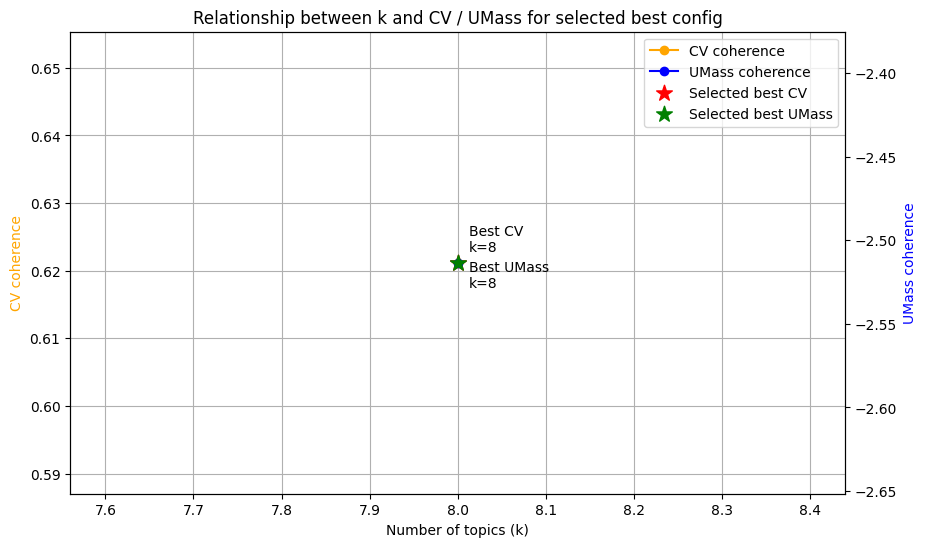

In [11]:
plot_df = plot_k_vs_cv_umass_for_best_config(best_output)

In [12]:

cleaned_df_with_topics, topic_assignment_info = assign_best_topics_to_cleaned_df_v2(
    cleaned_df=cleaned_df,
    results=evaluation_results,
    target_column=target_col_,
    target_col_=target_col_,
    summary=summary,
    best_output=best_output
)
cleaned_df_with_topics.to_csv(f"topic_modeling_results/cleaned_df_with_topics_{target_col_}_{summary}.csv")

with open(f"topic_modeling_results/topic_assignment_info_{target_col_}_{summary}.pkl", "wb") as f:
    pickle.dump(topic_assignment_info, f)

In [13]:
cleaned_df_with_topics

,primary_use_cases,key_technical_terms,system_design,readme,closed_issues,about,last_commit_date,open_issues,repo_full_name,merged_pr,repo_summary,forks,repository_intent,commits,stars,keywords,technical_focus,primary_use_cases_slightly_preprocessed,primary_use_cases_fully_preprocessed,primary_use_cases_keyword_initial_k_detected_topic
0,"enhancing reasoning, general conversation, ins...",NaN,"vllm framework, two-stage training pipeline, u...","<p align=""center"" width=""100%"">\n</p>\n\n<div ...",15,FuseAI Project,2025-01-25T06:37:54Z,15,18907305772/FuseAI,4,"1. repository_intent: knowledge fusion, large ...",45,"knowledge fusion, large language models, model...",111,87,"large-language-models, machine-learning, model...","model fusion techniques, long-CoT reasoning, s...",enhancing reasoning general conversation instr...,enhance reasoning conversation instruction fol...,5
1,"model evaluation, algorithm testing, research ...",NaN,"LLM architecture, serving framework, execution...",# 复现各种大模型相关算法\n,0,My LLM related projects and notes,2025-08-28T03:06:56Z,0,2572172469z-commits/llm-related,0,"1. repository_intent: LLM projects, algorithm ...",0,"LLM projects, algorithm reproduction, model ex...",2,0,NaN,"vllm, LLM serving, algorithm implementation, m...",evaluation algorithm testing research document...,testing research documentation performance ben...,-1
2,"dialogue applications, speech synthesis, inter...",NaN,"Python, PyTorch, torchaudio, command line inte...","<div align=""center"">\n\n<a href=""https://trend...",592,A generative speech model for daily dialogue.,2025-05-23T12:59:02Z,65,2noise/ChatTTS,216,"1. repository_intent: generative speech model,...",4079,"generative speech model, daily dialogue, text-...",421,37731,"agent, text-to-speech, chat, chatgpt, chattts,...","prosodic features, pretrained models, audio da...",dialogue applications speech synthesis interac...,dialogue application speech synthesis conversa...,2
3,"data cleaning, data imputation, data integrati...",NaN,"LLaMA-Factory integration, vllm framework, mod...",# KNOWTRANS: Boosting Transferability of Data ...,0,NaN,2025-03-01T11:27:58Z,0,A11en0/knowtrans,0,"1. repository_intent: knowledge augmentation, ...",0,"knowledge augmentation, data preparation, tran...",23,3,NaN,"KNOWTRANS, DP-LLMs, Jellyfish-7B, SKC, AKB, LL...",data cleaning data imputation data integration...,datum cleaning datum imputation datum integrat...,0
4,"training models, fine-tuning models, distribut...",NaN,"TPU architecture, VM management, command line ...","<div align=""center"">\n\n# torchprime\n\n#### H...",61,torchprime is a reference model implementation...,2025-09-03T16:48:48Z,89,AI-Hypercomputer/torchprime,182,1. repository_intent: reference model implemen...,9,"reference model implementation, PyTorch, TPU, ...",227,34,NaN,"torch_xla, TPU VM, distributed training, hydra...",training fine tuning distributed workloads clo...,training tuning distribute workload cloud tpu ...,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
591,"llm model compilation, inference optimization,...",NaN,"compiler and runtime, single kernel launch, ta...","<div align=""center"">\n\n# Mirage Persistent Ke...",81,Mirage Persistent Kernel: Compiling LLMs into ...,2026-02-23T15:58:16Z,172,mirage-project/mirage,304,"1. repository_intent: LLM inference, megakerne...",181,"LLM inference, megakernel compilation, GPU fus...",462,2149,NaN,"Mirage Persistent Kernel, fused GPU kernel, co...",compilation inference optimization performance...,inference optimization performance profiling r...,1
592,"rl training workload, policy evaluation, rollo...",NaN,"single-controller architecture, decoupled arch...","<p align=""center"">\n <img src=""https://raw....",46,Cosmos-RL is a flexible and scalable Reinforce...,2026-03-05T14:41:59Z,55,nvidia-cosmos/cosmos-rl,457,"1. repository_intent: Reinforcement Learning, ...",50,"Reinforcement Learning, Physical AI applicatio...",457,346,NaN,"Tenso

In [14]:
topic_desc_outputs = generate_topic_descriptions_for_best_and_initial(
    results=evaluation_results,
    best_output=best_output,
    max_keywords=10
)
with open(f"topic_modeling_results/topic_desc_outputs_{target_col_}_{summary}.pkl", "wb") as f:
    pickle.dump(topic_desc_outputs, f)

In [15]:
topic_desc_outputs

{'best_topic_descriptions':    topic_id  n_samples                                           keywords  \
 0         0        114  [reasoning, training, preparation, learning, p...   
 1         1        109  [serve, management, resource, ai, optimization...   
 2         2         78  [video, image, text, voice, audio, understandi...   
 3         3         44  [agent, training, agent training, tool, intera...   
 4         4         40  [retrieval, query, question, search, knowledge...   
 5         5         30  [chatbot, chat, interaction, agent, retrieval,...   
 6         6         25  [training, cod, math reasoning, reasoning, mat...   
 7         7         16  [code, execution, benchmark, testing, comparis...   
 
                                    topic_description  
 0  This topic mainly focuses on reasoning, traini...  
 1  This topic mainly focuses on serve, management...  
 2  This topic mainly focuses on video, image, and...  
 3  This topic mainly focuses on agent, train